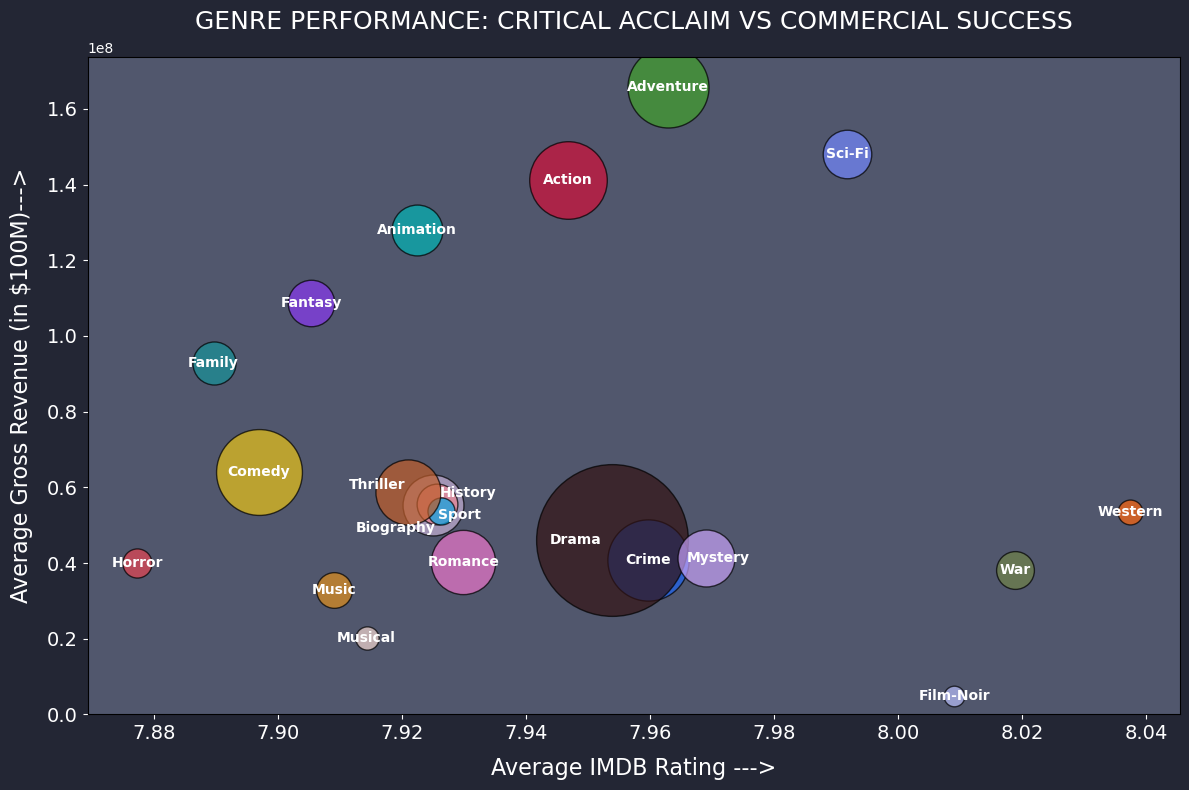

In [56]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("imdb_top_1000.csv")

df['Genre'] = df['Genre'].astype(str).str.split(', ') # Converts every value in the column into a string type and convert Genre column into a list by splitting on comma

df = df.explode('Genre') # Converts a list inside a cell into multiple rows, Create a new row for each genre in a movie.

df['Genre'] = df['Genre'].str.strip() # Removes extra spaces from the beginning and end of each Genre value.

df = df.dropna(subset=['Gross']) # Removes rows where the Gross column has missing (NaN) values (for efficiency).

df['Gross'] = df['Gross'].astype(str).str.replace('[\$,]', '', regex=True) # Converts Gross to string and removes "$" and "," to keep only numbers.

df['Gross'] = pd.to_numeric(df['Gross'], errors='coerce') # Converts the Gross column into numeric (number) type, and if any value cannot be converted, it replaces it with NaN.

genre_stats = df.groupby('Genre').agg({
    'IMDB_Rating': 'mean',      
    'Gross': 'mean',           
    'Series_Title': 'count'    
}).reset_index()        # Group data by Genre and calculate statistics

genre_stats.columns = ['Genre', 'Avg_IMDB', 'Avg_Gross', 'Movie_Count'] # Rename columns for clarity

genre_stats = genre_stats[genre_stats['Movie_Count'] >= 10] # Keeps only those genres that have at least 10 movies in the dataset.

genre_colors = {
    'Action': '#d20f39',
    'Adventure': '#40a02b',
    'Comedy': "#e9c317",
    'Drama': '#321212',
    'Sci-Fi': '#7287fd',
    'Horror': '#e64553',
    'Romance': '#ea76cb',
    'Animation': '#00b3b3',
    'Thriller': '#BF5C28',
    'Fantasy': '#8839ef',
    'Crime': '#1e66f5',
    'Mystery': '#c6a0f6',
    'Family': '#179299',
    'Music': '#df8e1d',
    'Biography': '#c5b0d5',
    'History': '#ed8796',
    'Sport': '#04a5e5',
    'War': '#6F8349',
    'Western': '#fe640b',
    'Film-Noir': '#b7bdf8',
    'Musical': '#f2d5cf'
}         # Creating a dictionary for color codes for each Genre bubbles


y_text_offsets = {
    'Thriller': 2e6,
    'Biography': -6e6,
    'History': 3e6,
    'Sport': -1e6
}         # Creating a dictionary for x position offset values for overlaping Genres

x_text_offsets = {
    'Drama': -0.006,
    'Sport': 0.003,
    'Mystery': 0.002,
    'Thriller': -0.005,
    'Biography': -0.006,
    'History': 0.005
}          # Creating a dictionary for x position offset values for overlaping Genres

plt.figure(figsize=(12, 8), facecolor='#232634') # Create the plot figure and change the outer bg color

plt.gca().set_facecolor('#51576d') # Change bgcolor of graph

# Draw scatter plot
for row in genre_stats.itertuples(index=False):
    plt.scatter(
        row.Avg_IMDB,                                     # X-axis values
        row.Avg_Gross,                                    # Y-axis values
        s=row.Movie_Count * 20,                           # Bubble size based on count
        alpha=0.7,                                        # For transparency
        edgecolors='#000000',                             # To fix edgecolor
        color=genre_colors.get(row.Genre, 'green')        # fallback color of bubbles
    )

# Add text labels for each genre point
for row in genre_stats.itertuples(index=False):
    y_offset = y_text_offsets.get(row.Genre, 0)       # Assigning y position offset values to y_offset
    x_offset = x_text_offsets.get(row.Genre, 0)       # Assigning x position offset values to x_offset
    plt.text(
        row.Avg_IMDB+x_offset,               # X position with offset values
        row.Avg_Gross+y_offset,              # Y position with offset values
        row.Genre,                           # Text label
        ha='center',                         # Horizontal alignment
        va='center',                         # Vertical alignment
        fontsize=10,                         # Font size
        color= '#ffffff',                    # Text color
        fontweight='bold'                    # Text type
    )

plt.xlabel("Average IMDB Rating --->", fontsize=16, color='#ffffff', labelpad=10) # Set label for X-axis and formating

plt.ylabel("Average Gross Revenue (in $100M)--->", fontsize=16, color='#ffffff', labelpad=10) # Set label for Y-axis and formating

plt.tick_params(axis='both', colors='#ffffff', labelsize=14) # Changes the appearance of the scale (ticks and numbers) on both axes

plt.title("GENRE PERFORMANCE: CRITICAL ACCLAIM VS COMMERCIAL SUCCESS", fontsize=18, color='#ffffff', pad=20) # Set main title of the plot

plt.tight_layout() # Adjust layout to avoid overlap

plt.ylim(0) # To choose the starting value of Y-axis to margin

plt.show() # Display the plot